---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 3. Population inference with an event-informed proposal

This page was generated from [`notebooks/gw/03_proposal_population.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/03_proposal_population.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/03_proposal_population.py`.

This notebook simulates a catalog of binary mergers from the population of notebook 1 and
infers its hyperparameters. The evidence of each event,
$Z_i(\Lambda)=\int \mathcal{L}(d_i\mid\theta)\,\pi(\theta\mid\Lambda)\,d\theta$, is estimated
by importance sampling from a proposal $q_\Lambda(\theta\mid d_i)$:

$$\hat Z_i(\Lambda)=\frac1N\sum_j \frac{\mathcal{L}(d_i\mid\theta_{ij})\,\pi(\theta_{ij}\mid\Lambda)}{q_\Lambda(\theta_{ij}\mid d_i)},
\qquad \theta_{ij}\sim q_\Lambda(\cdot\mid d_i).$$

The proposal treats two groups of parameters differently. The masses, redshift and projection
factor $(m_1, q, z, \Theta)$ are drawn from the region that the data $d_i$ point to. The spins
$\vec\chi = (\chi_1,\chi_2,\cos\theta_1,\cos\theta_2)$ are drawn from the population itself,
$\pi(\vec\chi\mid\Lambda)$. Because the spins come from the population's own distribution, that
factor cancels in the weight and is never evaluated:

$$w_{ij} = \frac{\mathcal{L}(d_i\mid\theta_{ij})\;\pi(m_1,q,z,\Theta\mid\Lambda)}{q(m_1,q,z,\Theta\mid d_i)}.$$

The draws are a fixed function of a stored key and $\Lambda$, so $\hat Z_i(\Lambda)$ is smooth in
$\Lambda$ and NUTS can use its gradient.

The catalog holds only detected events, so the likelihood is divided by the detected fraction
$\alpha(\Lambda)$ of the population. The notebook computes it from a fixed bank of population
draws and the detection probability of each draw, and compares it with the usual estimate from
injections.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

import json
import time
from pathlib import Path

import astroinfer as ai
import jax.numpy as jnp
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pandas as pd
import plot_helper as ph
from astroinfer import parameter, parameter_dataclass
from astroinfer_gw.gwmockcat import GWMockCatData, GWMockCatMeasurement, GWParams
from astroinfer_gw.physics import chirp_mass_from_mass_ratio, total_mass_from_chirp_mass
from astroinfer_gw.populations import PowerLaw, PowerLawRedshift, ProjectionFactor
from jax.scipy.stats import norm, truncnorm

ph.restore_plot_defaults()
ph.set_plot_defaults(latex_font_size=16, usetex=True)

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path(mo.notebook_dir())
RESULTS_DIR = NOTEBOOK_DIR.parent / "data" / "proposal_population"

N_TRUTHS = 20_000       # population draws to simulate
SNR_THRESHOLD = 4.0     # detected if the observed SNR exceeds this
N_EVENTS = 100          # detected events in the analysis
N_DRAWS = 2_000         # importance draws per event
N_BANK = 50_000         # fixed-bank draws for the selection term
N_INJECTIONS = 200_000  # injections, for comparison with the fixed bank

M_MIN, M_MAX = 5.0, 80.0   # primary mass range, in solar masses
Q_MIN = M_MIN / M_MAX      # smallest mass ratio the population allows
Z_MAX = 1.5

INFORMED_VARS = ["mass_1_source", "mass_ratio", "redshift", "projection_factor"]
SPIN_VARS = ["chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2"]

LABELS = dict(alpha=r"$\alpha$", beta=r"$\beta$", lamb=r"$\lambda$",
              mu_chi_1=r"$\mu_{\chi_1}$", sigma_chi_1=r"$\sigma_{\chi_1}$",
              mu_chi_2=r"$\mu_{\chi_2}$", sigma_chi_2=r"$\sigma_{\chi_2}$",
              mu_cos_tilt_1=r"$\mu_{t_1}$", sigma_cos_tilt_1=r"$\sigma_{t_1}$",
              mu_cos_tilt_2=r"$\mu_{t_2}$", sigma_cos_tilt_2=r"$\sigma_{t_2}$")
MASS_HYPER = ["alpha", "beta", "lamb"]
SPIN_HYPER = ["mu_chi_1", "sigma_chi_1", "mu_chi_2", "sigma_chi_2"]
TILT_HYPER = ["mu_cos_tilt_1", "sigma_cos_tilt_1", "mu_cos_tilt_2", "sigma_cos_tilt_2"]

## The population

The population is that of notebook 1, written again here: a structured distribution over
`GWParams` with a truncated power law in $m_1$, a power law in $q$ above $m_\mathrm{min}/m_1$,
`PowerLawRedshift` in $z$, $\Theta\sim\mathrm{Beta}(2,4)$, and truncated normals for the spin
magnitudes and tilt cosines. `PowerLaw`, `PowerLawRedshift` and `ProjectionFactor` come from
`astroinfer_gw.populations`.

The fields are written as two dictionaries, one for $(m_1, q, z, \Theta)$ and one for the spins,
so that three distributions can be built from the same fields:

- `population`, the joint $\pi(\theta\mid\Lambda)$ over `GWParams`;
- `informed_population`, the $(m_1,q,z,\Theta)$ marginal over a smaller type, `Informed`, which
  enters the weight and the selection term;
- `spin_population`, the spin marginal over `Spins`, which the proposal draws from.

The spins do not depend on the masses, so the joint density is the product of the two
marginals.

In [3]:
@parameter_dataclass(name="GW population hyperparameters", latex=r"\Lambda")
class GWHyper:
    alpha: float = parameter(name="Primary mass slope", latex=r"\alpha")
    beta: float = parameter(name="Mass ratio slope", latex=r"\beta")
    lamb: float = parameter(name="Redshift evolution", latex=r"\lambda")
    mu_chi_1: float = parameter(name="Mean primary spin magnitude", latex=r"\mu_{\chi_1}")
    sigma_chi_1: float = parameter(name="Width of primary spin magnitudes", latex=r"\sigma_{\chi_1}")
    mu_chi_2: float = parameter(name="Mean secondary spin magnitude", latex=r"\mu_{\chi_2}")
    sigma_chi_2: float = parameter(name="Width of secondary spin magnitudes", latex=r"\sigma_{\chi_2}")
    mu_cos_tilt_1: float = parameter(name="Mean primary tilt cosine", latex=r"\mu_{t_1}")
    sigma_cos_tilt_1: float = parameter(name="Width of primary tilt cosines", latex=r"\sigma_{t_1}")
    mu_cos_tilt_2: float = parameter(name="Mean secondary tilt cosine", latex=r"\mu_{t_2}")
    sigma_cos_tilt_2: float = parameter(name="Width of secondary tilt cosines", latex=r"\sigma_{t_2}")

@parameter_dataclass(name="Masses, redshift and projection factor", latex=r"\theta_m")
class Informed:
    mass_1_source: float = parameter(latex=r"m_1")
    mass_ratio: float = parameter(latex=r"q")
    redshift: float = parameter(latex=r"z")
    projection_factor: float = parameter(latex=r"\Theta")

@parameter_dataclass(name="Spins", latex=r"\vec\chi")
class Spins:
    chi_1: float = parameter(latex=r"\chi_1")
    chi_2: float = parameter(latex=r"\chi_2")
    cos_tilt_1: float = parameter(latex=r"\cos\theta_1")
    cos_tilt_2: float = parameter(latex=r"\cos\theta_2")

mass_fields = dict(
    mass_1_source=lambda L: PowerLaw(L.alpha, M_MIN, M_MAX),
    mass_ratio=ai.conditional(
        lambda x, L: PowerLaw(L.beta, M_MIN / x["mass_1_source"], 1.0, support=(0.0, 1.0)),
        on="mass_1_source"),
    redshift=lambda L: PowerLawRedshift(L.lamb, z_max=Z_MAX),
    projection_factor=ProjectionFactor(),
)
spin_fields = dict(
    chi_1=lambda L: dist.TruncatedNormal(L.mu_chi_1, L.sigma_chi_1, low=0.0, high=1.0),
    chi_2=lambda L: dist.TruncatedNormal(L.mu_chi_2, L.sigma_chi_2, low=0.0, high=1.0),
    cos_tilt_1=lambda L: dist.TruncatedNormal(L.mu_cos_tilt_1, L.sigma_cos_tilt_1, low=-1.0, high=1.0),
    cos_tilt_2=lambda L: dist.TruncatedNormal(L.mu_cos_tilt_2, L.sigma_cos_tilt_2, low=-1.0, high=1.0),
)

population = GWParams.distribution(**mass_fields, **spin_fields).given(GWHyper)
informed_population = Informed.distribution(**mass_fields).given(GWHyper)
spin_population = Spins.distribution(**spin_fields).given(GWHyper)

Lambda_true = GWHyper(alpha=-2.35, beta=1.1, lamb=2.7,
                      mu_chi_1=0.4, sigma_chi_1=0.05, mu_chi_2=0.0, sigma_chi_2=0.05,
                      mu_cos_tilt_1=0.8, sigma_cos_tilt_1=0.1, mu_cos_tilt_2=0.8, sigma_cos_tilt_2=0.1)
population

order,"mass_1_source, mass_ratio, redshift, projection_factor, chi_1, chi_2, cos_tilt_1, cos_tilt_2"


## Fixed-bank draws

A structured distribution draws through NumPyro, and astroinfer does not treat those draws as
differentiable in $\Lambda$. `as_generative()` converts it into a population that draws from a
fixed bank of uniform numbers by inverse transform sampling, so the same bank gives draws at
every $\Lambda$, and the draws are differentiable in $\Lambda$. Each random field becomes one
variable, in the distribution's draw order. The cell converts all three distributions and
compares their log densities on 2,000 draws:

In [4]:
bank = population.as_generative()
informed_bank = informed_population.as_generative()
spin_bank = spin_population.as_generative()

_draws = bank.sample(Lambda_true, seeds=bank.make_seeds(jax.random.key(10), N=2000))
_informed = Informed(**{v: _draws[v] for v in INFORMED_VARS})
_spins = Spins(**{v: _draws[v] for v in SPIN_VARS})
_lp_converted = bank.logpdf(_draws, Lambda_true)
_lp_structured = population.logpdf(_draws, Lambda_true)
_lp_split = (informed_bank.logpdf(_informed, Lambda_true)
             + spin_population.logpdf(_spins, Lambda_true))
bank_checks = {
    "order": bank.order,
    "largest |converted - structured| log density":
        float(jnp.max(jnp.abs(_lp_converted - _lp_structured))),
    "largest |joint - informed - spin| log density":
        float(jnp.max(jnp.abs(_lp_structured - _lp_split))),
}
bank_checks

{'order': ['mass_1_source',
  'mass_ratio',
  'redshift',
  'projection_factor',
  'chi_1',
  'chi_2',
  'cos_tilt_1',
  'cos_tilt_2'],
 'largest |converted - structured| log density': 3.552713678800501e-15,
 'largest |joint - informed - spin| log density': 3.552713678800501e-15}

In [5]:
mo.md(rf"""
The converted population's log density differs from the structured one by at most
{bank_checks["largest |converted - structured| log density"]:.1e}, and the joint log density
differs from the sum of the two marginals by at most
{bank_checks["largest |joint - informed - spin| log density"]:.1e}. The marginals take objects
of their own types, `Informed` and `Spins`, made here from the fields of the `GWParams` draws.

None of the three distributions from `astroinfer_gw.populations` is on the conversion's list of
closed-form inverse CDFs, so $m_1$, $q$, $z$ and $\Theta$ are drawn by bisection on their CDFs.
The spins, which are truncated normals, use the closed form.
""")

### Exploring the population

The sliders set the hyperparameters of the population shown in the plots below. They do not
change `Lambda_true`, so nothing further down the notebook re-runs. Each update draws from the
same bank, so the differences between settings come from $\Lambda$ and not from Monte Carlo
noise.

In [6]:
def _slider(lo, hi, value, step, label):
    return mo.ui.slider(lo, hi, value=value, step=step, label=label,
                        show_value=True, debounce=True)

explore_sliders = mo.ui.dictionary({
    "alpha": _slider(-5.0, 1.0, -2.35, 0.05, r"$\alpha$"),
    "beta": _slider(-2.0, 5.0, 1.1, 0.1, r"$\beta$"),
    "lamb": _slider(-2.0, 6.0, 2.7, 0.1, r"$\lambda$"),
    "mu_chi_1": _slider(0.0, 1.0, 0.4, 0.01, r"$\mu_{\chi_1}$"),
    "sigma_chi_1": _slider(0.02, 1.0, 0.05, 0.01, r"$\sigma_{\chi_1}$"),
    "mu_chi_2": _slider(0.0, 1.0, 0.0, 0.01, r"$\mu_{\chi_2}$"),
    "sigma_chi_2": _slider(0.02, 1.0, 0.05, 0.01, r"$\sigma_{\chi_2}$"),
    "mu_cos_tilt_1": _slider(-1.0, 1.0, 0.8, 0.01, r"$\mu_{t_1}$"),
    "sigma_cos_tilt_1": _slider(0.05, 2.0, 0.1, 0.01, r"$\sigma_{t_1}$"),
    "mu_cos_tilt_2": _slider(-1.0, 1.0, 0.8, 0.01, r"$\mu_{t_2}$"),
    "sigma_cos_tilt_2": _slider(0.05, 2.0, 0.1, 0.01, r"$\sigma_{t_2}$"),
})

_s = explore_sliders
explore_controls = mo.hstack([
    mo.vstack([mo.md("#### Masses and redshift"), _s["alpha"], _s["beta"], _s["lamb"]]),
    mo.vstack([mo.md("#### Spin magnitudes"), _s["mu_chi_1"], _s["sigma_chi_1"],
               _s["mu_chi_2"], _s["sigma_chi_2"]]),
    mo.vstack([mo.md("#### Tilt cosines"), _s["mu_cos_tilt_1"], _s["sigma_cos_tilt_1"],
               _s["mu_cos_tilt_2"], _s["sigma_cos_tilt_2"]]),
], justify="start", gap=2)
explore_controls

In [7]:
N_EXPLORE = 20_000
_seeds = bank.make_seeds(jax.random.key(123), N=N_EXPLORE)
# compiled once; the sliders only change the (traced) hyperparameter values
explore_sample = jax.jit(lambda L: bank.sample(GWHyper.from_dict(L), seeds=_seeds).to_dict())

In [8]:
POP_VARS = ["mass_1_source", "mass_ratio", "redshift", "chi_eff",
            "chi_1", "chi_2", "cos_tilt_1", "cos_tilt_2"]
POP_BINS = dict(mass_1_source=np.geomspace(M_MIN, M_MAX, 41),
                mass_ratio=np.linspace(Q_MIN, 1.0, 41),
                redshift=np.linspace(0.0, Z_MAX, 41),
                chi_eff=np.linspace(-1.0, 1.0, 41),
                chi_1=np.linspace(0.0, 1.0, 41), chi_2=np.linspace(0.0, 1.0, 41),
                cos_tilt_1=np.linspace(-1.0, 1.0, 41), cos_tilt_2=np.linspace(-1.0, 1.0, 41))
POP_LABELS = dict(mass_1_source=r"$m_1\ [M_\odot]$", mass_ratio=r"$q$", redshift=r"$z$",
                  chi_eff=r"$\chi_\mathrm{eff}$", chi_1=r"$\chi_1$", chi_2=r"$\chi_2$",
                  cos_tilt_1=r"$\cos\theta_1$", cos_tilt_2=r"$\cos\theta_2$")

def _with_chi_eff(x):
    x = {k: np.asarray(v) for k, v in x.items()}
    q = x["mass_ratio"]
    return {**x, "chi_eff": (x["chi_1"] * x["cos_tilt_1"]
                             + q * x["chi_2"] * x["cos_tilt_2"]) / (1.0 + q)}

def population_figure():
    """Empty 2x4 grid of one-dimensional marginals."""
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), layout="constrained")
    for ax, v in zip(axes.ravel(), POP_VARS):
        ax.set_xlabel(POP_LABELS[v])
        ax.set_xlim(POP_BINS[v][0], POP_BINS[v][-1])
    axes[0, 0].set(xscale="log", yscale="log")
    for ax in axes[:, 0]:
        ax.set_ylabel("density")
    return fig, axes

def plot_population(axes, x, *, color, label=None):
    """Draw one population on a `population_figure` grid.

    x : samples {var: (M,)} for one Lambda, or {var: (K, M)} for K hyperposterior draws,
        in which case each panel shows the median and 90% band over the draws.
    """
    x = _with_chi_eff(x)
    for i, (ax, v) in enumerate(zip(axes.ravel(), POP_VARS)):
        rows = np.atleast_2d(x[v])
        dens = np.stack([np.histogram(r, bins=POP_BINS[v], density=True)[0] for r in rows])
        lab = label if i == 0 else None
        if len(dens) > 1:
            lo, med, hi = np.quantile(dens, [0.05, 0.5, 0.95], axis=0)
            ax.stairs(hi, POP_BINS[v], baseline=lo, fill=True, color=color, alpha=0.3, linewidth=0)
            ax.stairs(med, POP_BINS[v], color=color, linewidth=1.5, label=lab)
        else:
            ax.stairs(dens[0], POP_BINS[v], color=color, linewidth=1.5, label=lab)

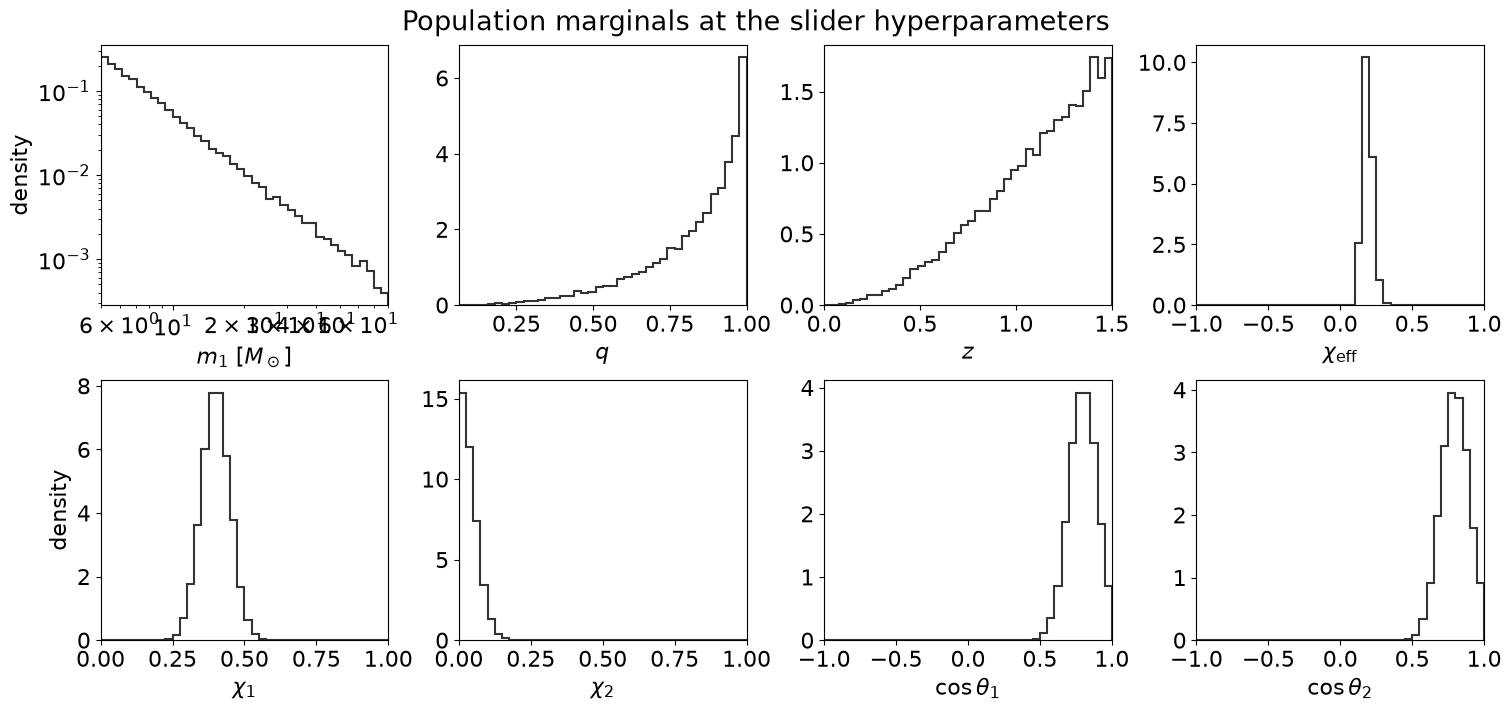

In [9]:
_L = {k: float(v) for k, v in explore_sliders.value.items()}
# plain mathtext keeps redraws fast (the notebook default renders through LaTeX)
with plt.rc_context({"text.usetex": False}):
    _fig, _axes = population_figure()
    plot_population(_axes, explore_sample(_L), color="0.2")
    _fig.suptitle("Population marginals at the slider hyperparameters")
_fig

## Simulating the catalog

The measurement process and trigger are those of notebook 1. The cell draws 20,000 sources at
the true $\Lambda$, simulates their data, and keeps the first 100 detected events:

In [10]:
measurement = GWMockCatMeasurement()
trigger = ai.detection.ThresholdTrigger(threshold=SNR_THRESHOLD, statistic="snr")

truths = population.sample(Lambda_true, key=0, N=N_TRUTHS)
observed = measurement.sample(truths, key=jax.random.key(1))
detected = trigger.detect(observed, np.random.default_rng(2))

_keep = np.flatnonzero(detected)[:N_EVENTS]
data = observed[_keep]

mo.md(f"{detected.sum():,} of {N_TRUTHS:,} sources are detected, and the analysis uses the first "
      f"{len(_keep)}. Their observed SNRs span {float(data.snr.min()):.1f} to "
      f"{float(data.snr.max()):.1f} (median {float(jnp.median(data.snr)):.1f}).")

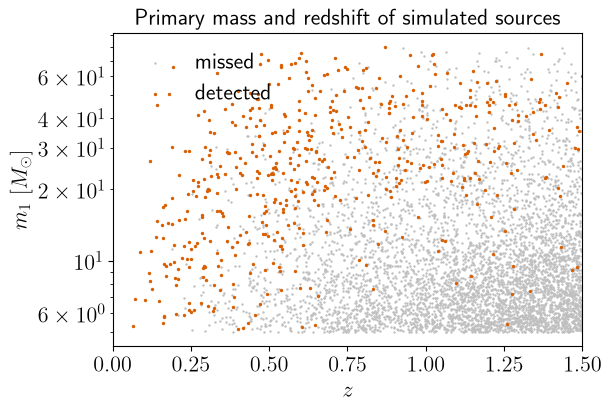

In [11]:
_fig, _ax = plt.subplots(figsize=(6, 4), layout="constrained")
_det = np.asarray(detected)
_m1, _z = np.asarray(truths.mass_1_source), np.asarray(truths.redshift)
_summary = mo.md(
    f"The plot shows the primary mass and redshift of the simulated sources. The detected "
    f"sources have a median $m_1$ of {np.median(_m1[_det]):.1f} $M_\\odot$ against "
    f"{np.median(_m1):.1f} $M_\\odot$ for all of them, and a median redshift of "
    f"{np.median(_z[_det]):.2f} against {np.median(_z):.2f}.")
_ax.scatter(_z[~_det][:5000], _m1[~_det][:5000], s=3, color="0.75", linewidths=0, label="missed")
_ax.scatter(_z[_det], _m1[_det], s=6, color=ph.default_pallete[1], linewidths=0, label="detected")
_ax.set(xlabel=r"$z$", ylabel=r"$m_1\ [M_\odot]$", yscale="log", xlim=(0, Z_MAX),
        title="Primary mass and redshift of simulated sources")
_ax.legend(frameon=False, loc="upper left")
mo.vstack([_summary, _fig])

## The proposal

For one event, the data restrict $(m_1, q, z, \Theta)$ to a small region. With $w=1/\hat\rho$, as in
the measurement model, the proposal draws:

* $\Theta\sim\mathcal{TN}(\hat\Theta,\ k_\Theta u_\Theta w)_{[0,1]}$, because the projection factor
  is observed directly;
* $\ln\mathcal{M}_\mathrm{det}\sim\mathcal N(\ln\hat{\mathcal M}_\mathrm{det},\ k_\mathcal{M}\,u_\mathcal{M}w)$,
  because the chirp mass is also observed directly;
* $q\sim U\big(q(\hat\eta - k_\eta u_\eta w),\ q(\hat\eta + k_\eta u_\eta w)\big)$, by inverting the
  symmetric mass ratio over a window of $\pm k_\eta$ standard deviations, which is wide near
  $q=1$, where $\eta$ is flat;
* $\ln z\mid\Theta\sim\mathcal N(\ln\hat z(\Theta),\ k_z/\hat\rho)$, where $\hat z(\Theta)$ solves
  $\rho_\mathrm{opt}(\mathcal M_\mathrm{det}, q, d_L(z))\,\Theta=\hat\rho$. This is centred on the
  drawn value of $\Theta$, so the proposal follows the ridge between the SNR, $\Theta$ and the
  distance.

From these, $m_1=\mathcal M_\mathrm{det}/\big[(1+z)\,c(q)\big]$, and $\log q(m_1,q,z,\Theta\mid d)$
includes the Jacobian of that transformation. Finally the spins are drawn from `spin_bank`, the
converted spin population, with their own key, so that they are also common random numbers
across $\Lambda$.

The proposal is a `Proposal`, a measurement process run backwards: its `parameter_type` is the
data class and its `data_type` is the parameter class. `Lambda` reaches `sample_single` and
`logpdf_single` as it was passed to the likelihood, a `GWHyper` in the checks below and a
dictionary inside the sampler. The converted and structured spin distributions accept either.

In [12]:
def q_of_eta(eta):
    eta = jnp.clip(eta, 1e-6, 0.25)
    return (1 - 2 * eta - jnp.sqrt(1 - 4 * eta)) / (2 * eta)


def truncnorm_draw(key, loc, scale, lo, hi):
    return loc + scale * jax.random.truncated_normal(key, (lo - loc) / scale, (hi - loc) / scale)


def truncnorm_logpdf(x, loc, scale, lo, hi):
    return truncnorm.logpdf(x, (lo - loc) / scale, (hi - loc) / scale, loc=loc, scale=scale)


class EventInformedProposal(ai.Proposal):
    """q_Lambda(theta | d) = q(m1, q, z, Theta | d) pi(spins | Lambda)."""

    parameter_type = GWMockCatData
    data_type = GWParams

    def __init__(self, measurement, spin_bank, k_mc=1.5, k_eta=4.0, k_theta=1.3, k_z=1.3, **kw):
        super().__init__(**kw)
        self.measurement, self.spin_bank = measurement, spin_bank
        self.k_mc, self.k_eta, self.k_theta, self.k_z = k_mc, k_eta, k_theta, k_z
        self._z_grid = jnp.asarray(measurement.cosmology.z)
        self._dl_grid = jnp.asarray(measurement.cosmology.d_L)

    def region(self, d):
        """Proposal parameters for (Theta, ln Mc_det, q) of event d."""
        m = self.measurement
        w = 1.0 / jnp.maximum(d.snr, m.snr_floor)
        de = self.k_eta * m.u_eta * w
        q_lo = jnp.maximum(q_of_eta(d.symmetric_mass_ratio - de), Q_MIN)
        q_hi = jnp.where(d.symmetric_mass_ratio + de >= 0.25, 1.0,
                         q_of_eta(d.symmetric_mass_ratio + de))
        return dict(theta_loc=d.projection_factor_obs, theta_sd=self.k_theta * m.u_projection * w,
                    ln_mc=d.log_chirp_mass_det, ln_mc_sd=self.k_mc * m.u_chirp_mass * w,
                    q_lo=q_lo, q_hi=jnp.maximum(q_hi, q_lo + 1e-3))

    def redshift_region(self, d, r, theta):
        """ln z mean and sd given Theta: solve snr = rho_opt(Mc_det, q, d_L(z)) * Theta for d_L."""
        snr_model = self.measurement.snr_model
        mc = jnp.exp(r["ln_mc"])
        m_tot = total_mass_from_chirp_mass(mc, 0.5 * (r["q_lo"] + r["q_hi"]))
        snr_hat = jnp.maximum(d.snr, 1.0)
        d_l = (snr_model.reference_snr * (mc / snr_model.reference_chirp_mass) ** (5 / 6)
               * snr_model.bns_horizon / (1 + (m_tot / snr_model.m_cut) ** 2) * theta / snr_hat)
        z_hat = jnp.clip(jnp.interp(d_l, self._dl_grid, self._z_grid), 1e-3, Z_MAX)
        return jnp.log(z_hat), self.k_z / snr_hat

    def sample_single(self, d, key, Lambda):
        k_theta, k_mc, k_q, k_z, k_spin = jax.random.split(key, 5)
        r = self.region(d)
        theta = truncnorm_draw(k_theta, r["theta_loc"], r["theta_sd"], 0.0, 1.0)
        mc_det = jnp.exp(r["ln_mc"] + r["ln_mc_sd"] * jax.random.normal(k_mc))
        q = r["q_lo"] + (r["q_hi"] - r["q_lo"]) * jax.random.uniform(k_q)
        ln_z, ln_z_sd = self.redshift_region(d, r, theta)
        z = jnp.exp(ln_z + ln_z_sd * jax.random.normal(k_z))
        m1 = mc_det / ((1 + z) * chirp_mass_from_mass_ratio(1.0, q))
        spins = self.spin_bank.sample(Lambda, key=k_spin)
        return GWParams(mass_1_source=m1, mass_ratio=q, redshift=z, projection_factor=theta,
                        **{v: spins[v] for v in SPIN_VARS})

    def log_q_informed(self, theta, d):
        """log q(m1, q, z, Theta | d), with the Jacobian of (ln Mc_det, ln z) -> (m1, z)."""
        r = self.region(d)
        m1, q, z = theta.mass_1_source, theta.mass_ratio, theta.redshift
        ln_z, ln_z_sd = self.redshift_region(d, r, theta.projection_factor)
        mc_det = m1 * chirp_mass_from_mass_ratio(1.0, q) * (1 + z)
        return (truncnorm_logpdf(theta.projection_factor, r["theta_loc"], r["theta_sd"], 0.0, 1.0)
                + norm.logpdf(jnp.log(mc_det), r["ln_mc"], r["ln_mc_sd"]) - jnp.log(m1)
                + jnp.where((q >= r["q_lo"]) & (q <= r["q_hi"]),
                            -jnp.log(r["q_hi"] - r["q_lo"]), -jnp.inf)
                + norm.logpdf(jnp.log(z), ln_z, ln_z_sd) - jnp.log(z))

    def logpdf_single(self, theta, d, Lambda):
        spins = Spins(**{v: theta[v] for v in SPIN_VARS})
        return self.log_q_informed(theta, d) + spin_population.logpdf(spins, Lambda)

## The selection term

The trigger thresholds the observed SNR, which the measurement draws as
$\hat\rho\sim\mathcal N(\rho(\theta), 1)$. The probability that a source with parameters
$\theta$ is detected is therefore

$$P(\mathrm{det}\mid\theta) = \Phi\big(\rho(\theta) - \rho_\mathrm{th}\big),$$

where $\rho(\theta)$ is `measurement.true_snr(theta)` and $\rho_\mathrm{th} = 4$. It depends
only on $(m_1, q, z, \Theta)$. The detected fraction is its average over the population,
$\alpha(\Lambda) = \mathbb{E}_{\pi(\theta\mid\Lambda)}\big[P(\mathrm{det}\mid\theta)\big]$,
which we estimate as the mean over a fixed bank of 50,000 draws from `informed_bank`. Because
the bank does not change, the estimate is a smooth function of $\Lambda$. Its effective number
of draws is $(\sum_j p_j)^2/\sum_j p_j^2$, with $p_j = P(\mathrm{det}\mid\theta_j)$.

The usual alternative is to reweight injections. They are drawn once from a broad distribution
$g$, the injection distribution of notebook 1, measured, and passed through the trigger. With
$N_\mathrm{inj}$ injections,

$$\hat\alpha_\mathrm{inj}(\Lambda)=\frac{1}{N_\mathrm{inj}}\sum_{\mathrm{found}}
\frac{\pi(m_1,q,z,\Theta\mid\Lambda)}{g(m_1,q,z,\Theta)}.$$

The spins of $g$ do not affect detection, so only the $(m_1, q, z, \Theta)$ factors enter the
ratio.

In [13]:
def detection_probability(theta):
    """P(det | theta) = Phi(rho(theta) - threshold), for the trigger on the observed SNR."""
    return norm.cdf(measurement.true_snr(theta) - SNR_THRESHOLD)

_bank_seeds = informed_bank.make_seeds(jax.random.key(7), N=N_BANK)

def bank_selection(Lambda):
    """log alpha(Lambda) and its effective number of draws, from the fixed bank."""
    p = detection_probability(informed_bank.sample(Lambda, seeds=_bank_seeds))
    return jnp.log(jnp.mean(p)), jnp.sum(p) ** 2 / jnp.sum(p**2)

In [14]:
injection_fields = dict(
    mass_1_source=PowerLaw(-1.5, 4.0, 120.0),
    mass_ratio=dist.Uniform(0.05, 1.0),
    redshift=PowerLawRedshift(1.0, z_max=Z_MAX),
    projection_factor=ProjectionFactor(),
    chi_1=dist.Uniform(0.0, 1.0),
    chi_2=dist.Uniform(0.0, 1.0),
    cos_tilt_1=dist.Uniform(-1.0, 1.0),
    cos_tilt_2=dist.Uniform(-1.0, 1.0),
)
injection_population = GWParams.distribution(**injection_fields)
# g over (m1, q, z, Theta) only: the same fields without the spins
_g_informed = Informed.distribution(**{v: injection_fields[v] for v in INFORMED_VARS})

_draws = injection_population.sample(key=5, N=N_INJECTIONS)
_found = trigger.detect(measurement.sample(_draws, key=jax.random.key(6)),
                        np.random.default_rng(7))
_found_informed = Informed(**{v: _draws[v][_found] for v in INFORMED_VARS})
_log_g = _g_informed.logpdf(_found_informed)

def injection_selection(Lambda):
    """log alpha(Lambda) and its effective number of injections, reweighting found injections."""
    log_r = informed_bank.logpdf(_found_informed, Lambda) - _log_g
    lse = jax.scipy.special.logsumexp(log_r)
    return lse - jnp.log(N_INJECTIONS), jnp.exp(2 * lse - jax.scipy.special.logsumexp(2 * log_r))

mo.md(f"{int(_found.sum()):,} of {N_INJECTIONS:,} injections are found.")

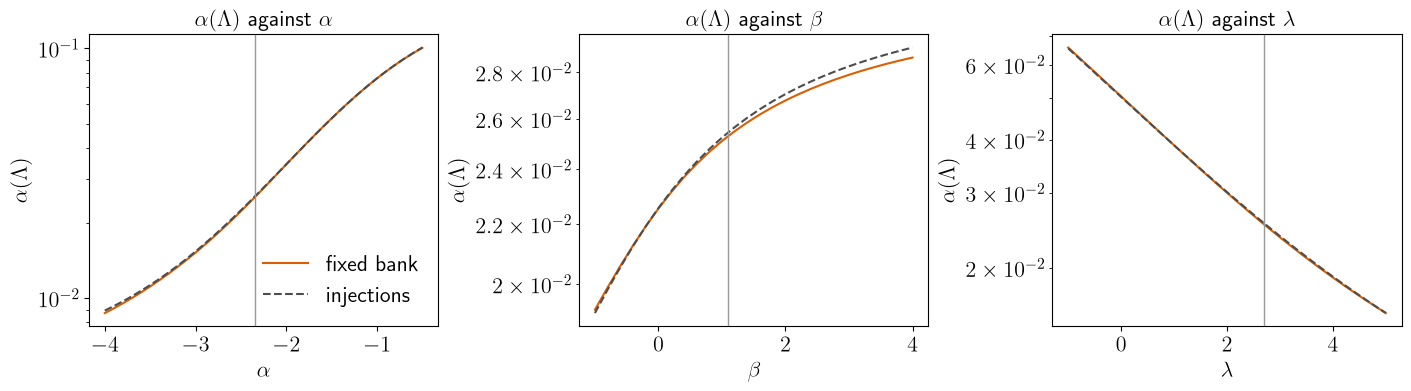

In [15]:
def _vary(name, values):
    base = Lambda_true.to_dict()
    return GWHyper(**{**base, name: jnp.asarray(values)}).broadcast((len(values),))

_bank_true = [float(v) for v in jax.jit(bank_selection)(Lambda_true)]
_inj_true = [float(v) for v in jax.jit(injection_selection)(Lambda_true)]

_fig, _axes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
for _ax, (_name, _grid) in zip(_axes, [("alpha", np.linspace(-4.0, -0.5, 36)),
                                       ("beta", np.linspace(-1.0, 4.0, 26)),
                                       ("lamb", np.linspace(-1.0, 5.0, 31))]):
    _L = _vary(_name, _grid)
    _b = jax.vmap(lambda L: bank_selection(L)[0])(_L)
    _i = jax.vmap(lambda L: injection_selection(L)[0])(_L)
    _ax.plot(_grid, np.exp(_b), color=ph.default_pallete[1], label="fixed bank")
    _ax.plot(_grid, np.exp(_i), color="0.3", linestyle="--", label="injections")
    _ax.axvline(getattr(Lambda_true, _name), color="0.6", linewidth=1)
    _ax.set(xlabel=LABELS[_name], ylabel=r"$\alpha(\Lambda)$", yscale="log",
            title=rf"$\alpha(\Lambda)$ against {LABELS[_name]}")
_axes[0].legend(frameon=False)

mo.vstack([
    mo.md(f"At the true $\\Lambda$ the fixed bank gives $\\alpha$ = {np.exp(_bank_true[0]):.4f} "
          f"with $N_\\mathrm{{eff}}$ = {_bank_true[1]:,.0f}, and the injections give "
          f"{np.exp(_inj_true[0]):.4f} with $N_\\mathrm{{eff}}$ = {_inj_true[1]:,.0f}. "
          "The plots vary one hyperparameter at a time, with the others at their true values; "
          "the grey line marks the truth."),
    _fig,
])

## The likelihood with selection

The likelihood subclasses `PopulationLikelihood`. It overrides `log_weights` with the weight
above, in which the spin factor cancels, and `logpdf` to subtract the selection term from the
fixed bank:

$$\ln\mathcal L(\Lambda)=\sum_i\ln\hat Z_i(\Lambda) - N_\mathrm{events}\ln\hat\alpha(\Lambda).$$

The weight evaluates $\pi(m_1,q,z,\Theta\mid\Lambda)$ with `informed_bank.logpdf`, the converted
population's density, rather than `informed_population.logpdf`. Both give the same numbers, but
the structured distribution builds the distribution of each field once per draw, so for the
200,000 draws of one evaluation it recomputes the redshift normalization 200,000 times; the
converted one computes it once per evaluation. With the structured density, one evaluation of
the likelihood and its gradient takes about ten times longer.

In [16]:
class SpinCancelledLikelihood(ai.PopulationLikelihood):
    """log w = log L + log pi(m1, q, z, Theta | Lambda) - log q(m1, q, z, Theta | d); the spins
    cancel. logpdf subtracts E log alpha(Lambda), with alpha from `selection(Lambda)`."""

    def __init__(self, *args, informed_bank, selection, **kw):
        super().__init__(*args, **kw)
        self.informed_bank = informed_bank
        self.selection = selection

    def log_weights(self, Lambda):
        theta = self.proposal_draws(Lambda)
        d = self.data.reshape_batch((self.E, 1))
        informed = Informed(**{v: theta[v] for v in INFORMED_VARS})
        return (self.log_likelihood_at(theta)
                + self.informed_bank.logpdf(informed, Lambda)
                - self.proposal.log_q_informed(theta, d))

    def logpdf(self, Lambda):
        log_l = super().logpdf(Lambda)
        log_alpha, n_eff = self.selection(Lambda)
        self.diagnostics = {**self.diagnostics, "N_eff_selection": n_eff}
        return log_l - self.E * log_alpha

In [17]:
proposal = EventInformedProposal(measurement, spin_bank)

def make_likelihood(seed):
    return SpinCancelledLikelihood(
        measurement, data, population, N=N_DRAWS, seed=seed, proposal=proposal,
        informed_bank=informed_bank, selection=bank_selection)

likelihood = make_likelihood(seed=3)
proposal

EventInformedProposal()

## Checks at the true $\Lambda$

Before sampling, we check the effective sample size of each event at the true $\Lambda$, the
Monte Carlo scatter of $\sum_i\ln\hat Z_i$ between two independent proposal keys, and that the
default weight of `PopulationLikelihood`, $\mathcal{L}\,\pi(\theta\mid\Lambda)/q_\Lambda(\theta\mid d)$,
which evaluates the spin factor in both $\pi$ and $q$, gives the same evidence.

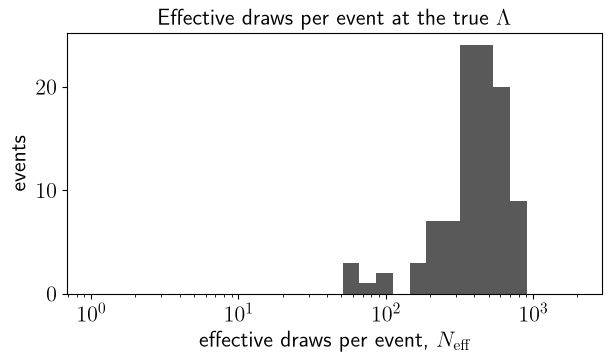

In [18]:
_lp, n_eff_true = jax.jit(likelihood.event_logpdf_and_neff)(Lambda_true)
_lp_other, _ = jax.jit(make_likelihood(seed=11).event_logpdf_and_neff)(Lambda_true)
_default = ai.PopulationLikelihood(measurement, data, population, N=N_DRAWS, seed=3,
                                   proposal=proposal)
_lp_default, _ = jax.jit(_default.event_logpdf_and_neff)(Lambda_true)
_log_alpha, _n_eff_sel = likelihood.selection(Lambda_true)

_fig, _ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
_ax.hist(np.asarray(n_eff_true), bins=np.geomspace(1, N_DRAWS, 30), color="0.35")
_ax.set(xscale="log", xlabel=r"effective draws per event, $N_\mathrm{eff}$", ylabel="events",
        title=r"Effective draws per event at the true $\Lambda$")

mo.vstack([
    mo.md(
        f"Out of {N_DRAWS:,} draws per event, the median $N_\\mathrm{{eff}}$ is "
        f"{float(jnp.median(n_eff_true)):.0f} and the minimum is {float(n_eff_true.min()):.1f}. "
        f"Two proposal keys give $\\sum_i\\ln\\hat Z_i$ = {float(_lp.sum()):.2f} and "
        f"{float(_lp_other.sum()):.2f}, and the default weight gives "
        f"{float(_lp_default.sum()):.2f} with the first key. The selection term has "
        f"$N_\\mathrm{{eff}}$ = {float(_n_eff_sel):,.0f}, which should be much larger than "
        f"$4N_\\mathrm{{events}}$ = {4 * N_EVENTS}."),
    _fig,
])

## Hyperparameter inference

The hyperprior is uniform in each hyperparameter. `ai.run_sampler` runs NUTS on the likelihood
above, with a dense mass matrix, and records the likelihood's diagnostics with every draw.

The samples are saved in `notebooks/data/proposal_population/`, together with the settings
that produced them (the true $\Lambda$, the numbers of events and draws, and the observed
SNRs). They are loaded on later runs if those settings match, unless you tick the box.

In [19]:
hyper_priors = dict(
    alpha=dist.Uniform(-5.0, 1.0), beta=dist.Uniform(-2.0, 5.0), lamb=dist.Uniform(-2.0, 6.0),
    mu_chi_1=dist.Uniform(0.0, 1.0), sigma_chi_1=dist.Uniform(0.02, 1.0),
    mu_chi_2=dist.Uniform(0.0, 1.0), sigma_chi_2=dist.Uniform(0.02, 1.0),
    mu_cos_tilt_1=dist.Uniform(-1.0, 1.0), sigma_cos_tilt_1=dist.Uniform(0.05, 2.0),
    mu_cos_tilt_2=dist.Uniform(-1.0, 1.0), sigma_cos_tilt_2=dist.Uniform(0.05, 2.0),
)
force_run = mo.ui.checkbox(label="re-run the sampler (overwrites data/proposal_population)")
force_run

In [20]:
_path = RESULTS_DIR / "hyperposterior.csv"
_settings_path = RESULTS_DIR / "settings.json"
_settings = {"Lambda_true": {k: round(float(v), 6) for k, v in Lambda_true.to_dict().items()},
             "N_EVENTS": N_EVENTS, "N_DRAWS": N_DRAWS, "N_BANK": N_BANK,
             "hyperpriors": sorted(hyper_priors),
             "snr": [round(float(s), 6) for s in np.asarray(data.snr)]}
_cached = (_path.exists() and _settings_path.exists() and not force_run.value
           and json.loads(_settings_path.read_text()) == _settings)
if _cached:
    hyperposterior = pd.read_csv(_path)
    mc_runtime = None
else:
    _t0 = time.perf_counter()
    _sampler = ai.run_sampler(likelihood, hyper_priors, seed=1, num_warmup=500,
                              num_samples=1000, summary=False,
                              sampler_kwargs={"dense_mass": True})
    mc_runtime = time.perf_counter() - _t0
    hyperposterior = _sampler.samples
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    hyperposterior.to_csv(_path, index=False)
    _settings_path.write_text(json.dumps(_settings))
hyperposterior.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
N_eff_mean,384.808301,31.127392,282.190879,497.916388
N_eff_min,30.709374,16.160778,4.929062,112.558791
N_eff_min_fraction,0.015355,0.008080,0.002465,0.056279
N_eff_selection,2844.000852,614.309702,1559.511533,6141.701747
alpha,-2.094728,0.179104,-2.612632,-1.562885
beta,0.813781,0.321077,-0.198573,1.866448
lamb,2.683730,0.672119,-0.214653,4.644499
log_likelihood,167.186552,2.091311,156.705587,171.024305
mu_chi_1,0.402244,0.254661,0.000219,0.999025
mu_chi_2,0.424077,0.277975,0.000239,0.994635


In [21]:
_time = "" if mc_runtime is None else f"The run took {mc_runtime / 60:.0f} minutes. "
mo.md(f"""
{_time}Along the chain, the smallest per-event $N_\\mathrm{{eff}}$ has a median of
{hyperposterior['N_eff_min'].median():.1f} and a minimum of {hyperposterior['N_eff_min'].min():.1f}.
The smallest selection $N_\\mathrm{{eff}}$ is {hyperposterior['N_eff_selection'].min():,.0f}.
""")

## The hyperposterior

The table gives the posterior mean and standard deviation of each hyperparameter, its 90%
credible interval, and the distance of the mean from the true value in standard deviations.
The corner plots below show the same draws, with the true values marked.

In [22]:
_rows = []
for _k in LABELS:
    _x = hyperposterior[_k]
    _truth = float(getattr(Lambda_true, _k))
    _rows.append({"hyperparameter": _k, "truth": _truth, "mean": _x.mean(), "sd": _x.std(),
                  "5%": _x.quantile(0.05), "95%": _x.quantile(0.95),
                  "(mean - truth) / sd": (_x.mean() - _truth) / _x.std()})
hyper_summary = pd.DataFrame(_rows).set_index("hyperparameter").round(3)
hyper_summary

,truth,mean,sd,5%,95%,(mean - truth) / sd
hyperparameter,,,,,,
alpha,-2.35,-2.095,0.179,-2.377,-1.793,1.425
beta,1.10,0.814,0.321,0.287,1.342,-0.891
lamb,2.70,2.684,0.672,1.581,3.711,-0.024
mu_chi_1,0.40,0.402,0.255,0.052,0.877,0.009
sigma_chi_1,0.05,0.373,0.282,0.046,0.909,1.148
mu_chi_2,0.00,0.424,0.278,0.034,0.914,1.526
sigma_chi_2,0.05,0.491,0.277,0.072,0.948,1.592
mu_cos_tilt_1,0.80,0.454,0.256,0.131,0.904,-1.348
sigma_cos_tilt_1,0.10,0.232,0.252,0.059,0.631,0.523


In [23]:
_s = hyper_summary
_inside = int(((_s["5%"] <= _s["truth"]) & (_s["truth"] <= _s["95%"])).sum())
mo.md(f"""
The true value lies inside the 90% interval for {_inside} of the {len(_s)} hyperparameters.
The primary mass slope is $\\alpha = {_s.loc["alpha", "mean"]:.2f} \\pm {_s.loc["alpha", "sd"]:.2f}$
(true value {_s.loc["alpha", "truth"]:g}), and the redshift evolution is
$\\lambda = {_s.loc["lamb", "mean"]:.2f} \\pm {_s.loc["lamb", "sd"]:.2f}$ (true value
{_s.loc["lamb", "truth"]:g}). The spins enter the data only through $\\chi_\\mathrm{{eff}}$ and
$\\chi_p$, which the measurement determines to $0.8/\\hat\\rho$ and $7.2/\\hat\\rho$, so the spin
hyperparameters are less well constrained than the mass and redshift ones.
""")

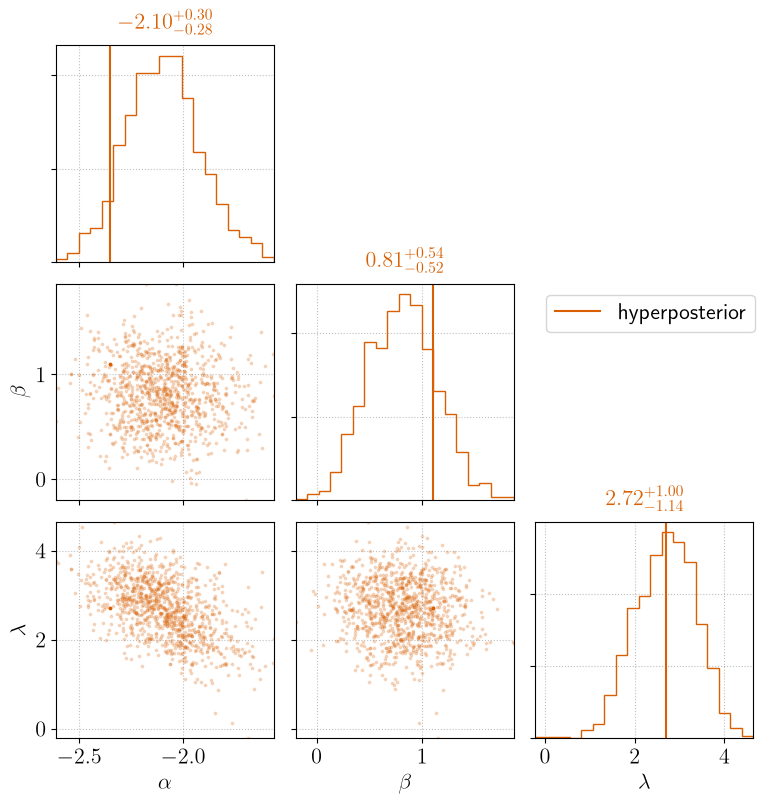

In [24]:
_fig, _ = ph.make_corner_plot(
    [hyperposterior[MASS_HYPER]], model_labels=["hyperposterior"], variables=MASS_HYPER,
    variable_labels=[LABELS[v] for v in MASS_HYPER],
    truth={v: float(getattr(Lambda_true, v)) for v in MASS_HYPER},
    scatter_kwargs=dict(s=3, alpha=0.2))
_fig

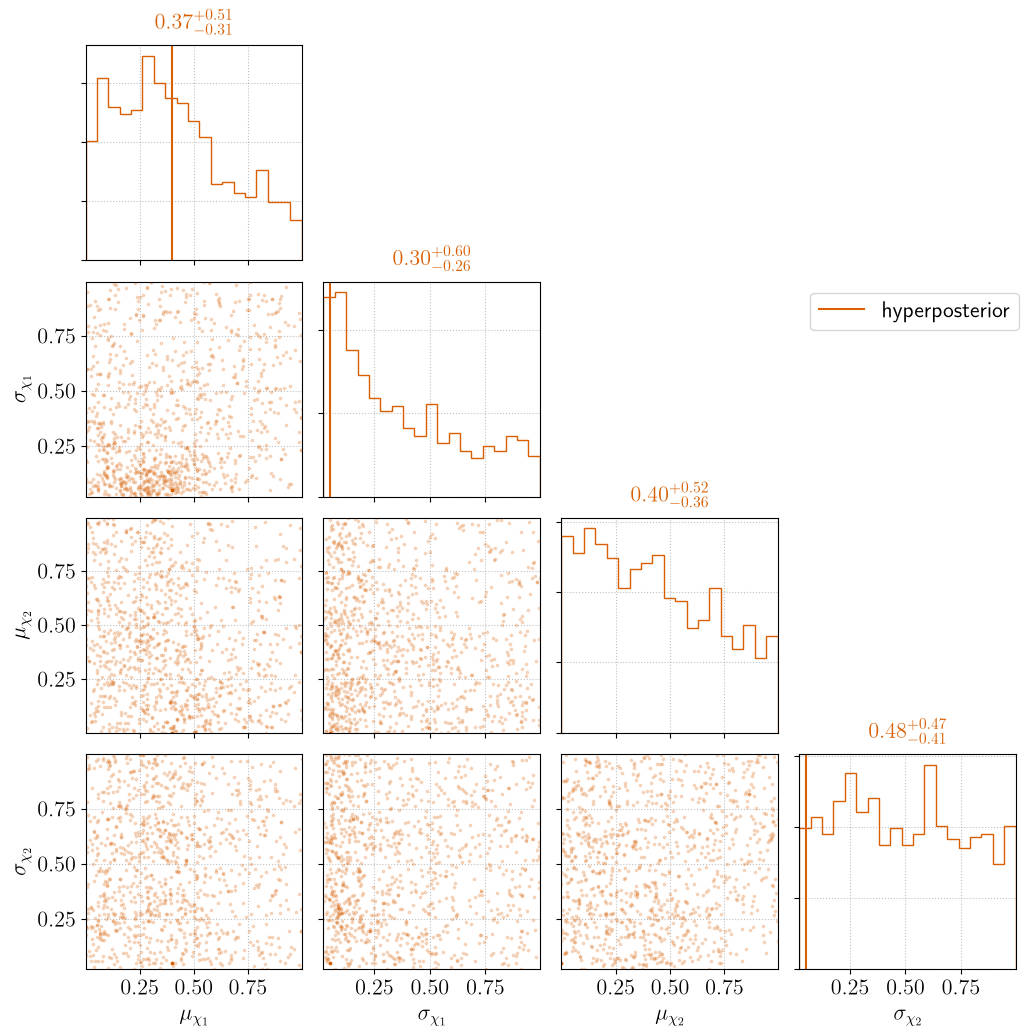

In [25]:
_fig, _ = ph.make_corner_plot(
    [hyperposterior[SPIN_HYPER]], model_labels=["hyperposterior"], variables=SPIN_HYPER,
    variable_labels=[LABELS[v] for v in SPIN_HYPER],
    truth={v: float(getattr(Lambda_true, v)) for v in SPIN_HYPER},
    scatter_kwargs=dict(s=3, alpha=0.2))
_fig

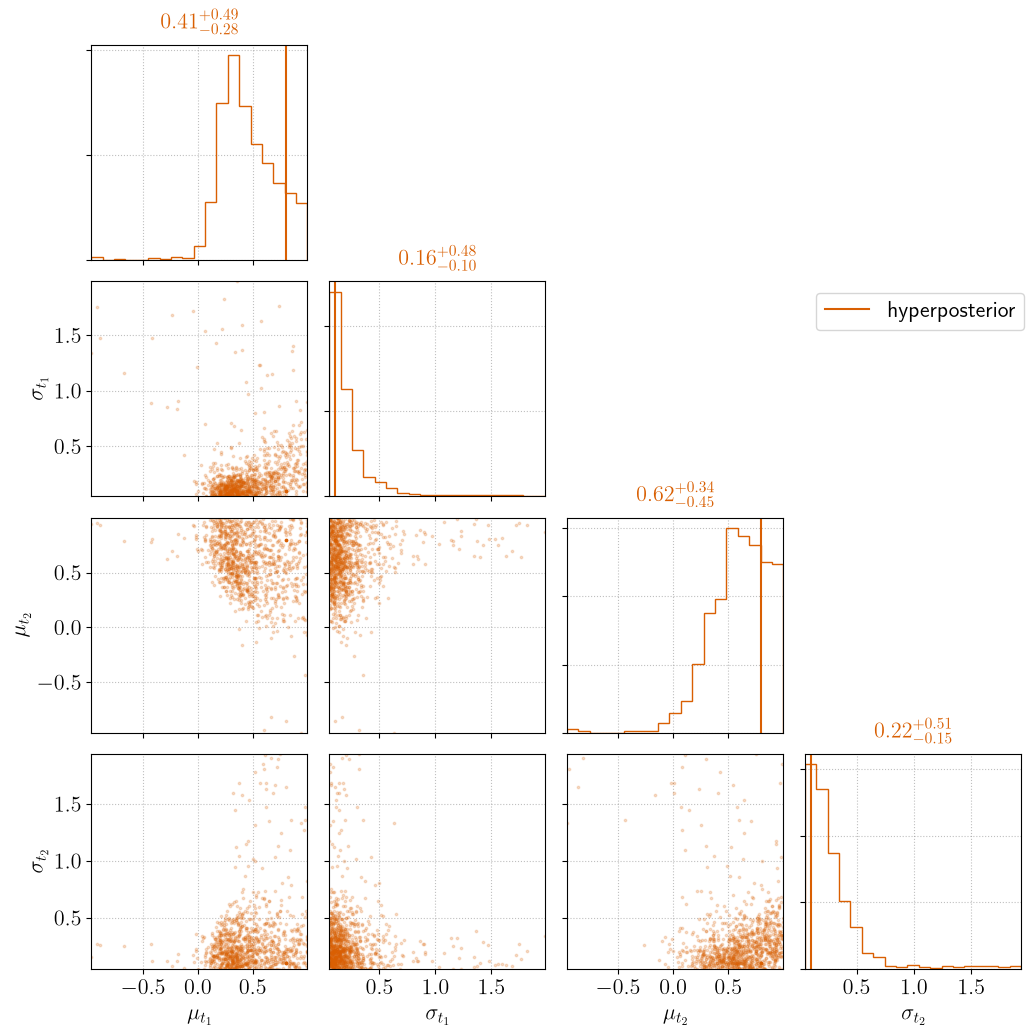

In [26]:
_fig, _ = ph.make_corner_plot(
    [hyperposterior[TILT_HYPER]], model_labels=["hyperposterior"], variables=TILT_HYPER,
    variable_labels=[LABELS[v] for v in TILT_HYPER],
    truth={v: float(getattr(Lambda_true, v)) for v in TILT_HYPER},
    scatter_kwargs=dict(s=3, alpha=0.2))
_fig

## Population predictive distribution

These panels show the population averaged over the hyperposterior, on the same axes as the
explorer above, using 200 hyperposterior draws with 5,000 sources each, drawn from the fixed
bank. Each panel shows the median and 90% band across draws. The band includes some Monte
Carlo noise from using 5,000 sources per draw.

The grey reference is the population set by the sliders, which are shown again here. They start
at the true values, so by default the grey reference is the true population.

In [27]:
N_PPD_HYPER, N_PPD_DRAWS = 200, 5_000
_rows = hyperposterior.iloc[np.linspace(0, len(hyperposterior) - 1, N_PPD_HYPER).astype(int)]
_Lambda = GWHyper(**{k: jnp.asarray(_rows[k].to_numpy()) for k in GWHyper.field_specs()})
_seeds = bank.make_seeds(jax.random.key(321), N=N_PPD_DRAWS)
_draw = jax.jit(jax.vmap(lambda L: bank.sample(L, seeds=_seeds).to_dict()))
ppd = {k: np.asarray(v) for k, v in _draw(_Lambda).items()}   # {var: (N_PPD_HYPER, N_PPD_DRAWS)}

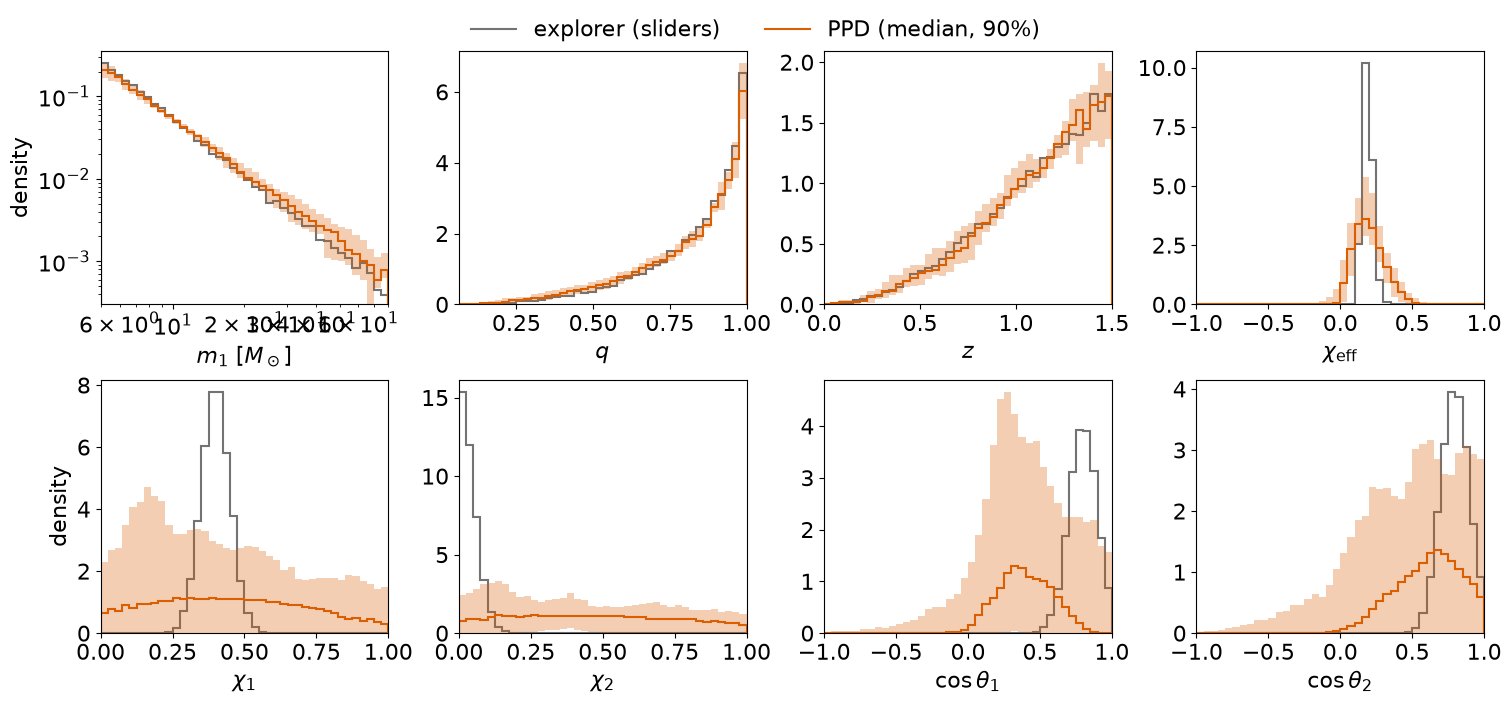

In [28]:
_L = {k: float(v) for k, v in explore_sliders.value.items()}
with plt.rc_context({"text.usetex": False}):
    _fig, _axes = population_figure()
    plot_population(_axes, explore_sample(_L), color="0.45", label="explorer (sliders)")
    plot_population(_axes, ppd, color=ph.default_pallete[1], label="PPD (median, 90%)")
    _fig.legend(loc="outside upper center", ncols=2, frameon=False)
mo.vstack([explore_controls, _fig])